### Setup and inspect the datasets

In [69]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score


pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

In [70]:

customers = pd.read_csv("C:\\Users\\lakshraj computer\\Downloads\\QuickCart_Assessment_Keval_Chauhan\\quickcart_data\\customers.csv")
customers.head()

,customer_id,signup_date,city,age,gender,plan_type,acquisition_channel,account_status
0,C00001,2025-07-27,Bengaluru,23.0,F,free,organic,active
1,C00002,2026-02-18,Pune,35.0,M,plus,organic,active
2,C00003,2026-01-13,Jaipur,26.0,F,free,referral,active
3,C00004,2025-11-09,Bengaluru,18.0,M,premium,google_ads,active
4,C00005,2025-11-07,Ahmedabad,29.0,M,free,referral,active


In [71]:
orders_data = pd.read_csv("C:\\Users\\lakshraj computer\\Downloads\\QuickCart_Assessment_Keval_Chauhan\\quickcart_data\\orders.csv")
orders_data.head()

,order_id,customer_id,order_ts,basket_value,items_count,discount_amt,distance_km,store_open_orders,is_raining,delivery_minutes,payment_method,status
0,O0065098,C02442,2025-07-02 04:25:57.424918,518.71,13,0.00,1.63,4,0,20.5,COD,delivered
1,O0040713,C01550,2025-07-03 03:51:16.974293,429.40,10,21.47,1.77,15,0,26.6,card,delivered
2,O0085074,C03191,2025-07-03 04:56:28.375695,298.22,7,14.91,1.83,4,1,26.5,card,delivered
3,O0022172,C00845,2025-07-03 14:19:33.378437,296.85,3,0.00,1.96,5,0,14.5,UPI,refunded
4,O0086160,C03234,2025-07-03 14:41:18.888420,697.31,13,139.46,2.36,26,1,34.3,UPI,delivered


In [72]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          4000 non-null   str    
 1   signup_date          4000 non-null   str    
 2   city                 4000 non-null   str    
 3   age                  3940 non-null   float64
 4   gender               4000 non-null   str    
 5   plan_type            4000 non-null   str    
 6   acquisition_channel  4000 non-null   str    
 7   account_status       4000 non-null   str    
dtypes: float64(1), str(7)
memory usage: 418.0 KB


In [73]:
orders_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 106592 entries, 0 to 106591
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   order_id           106592 non-null  str    
 1   customer_id        106592 non-null  str    
 2   order_ts           106592 non-null  str    
 3   basket_value       106592 non-null  float64
 4   items_count        106592 non-null  int64  
 5   discount_amt       106592 non-null  float64
 6   distance_km        106592 non-null  float64
 7   store_open_orders  106592 non-null  int64  
 8   is_raining         106592 non-null  int64  
 9   delivery_minutes   101352 non-null  float64
 10  payment_method     106592 non-null  str    
 11  status             106592 non-null  str    
dtypes: float64(4), int64(3), str(5)
memory usage: 15.1 MB


### Missing values report

In [74]:
customer_cat_cols = [
    "city",
    "gender",
    "plan_type",
    "acquisition_channel",
    "account_status"
]

order_cat_cols = [
    "payment_method",
    "status"
]

In [75]:
miss_cust = customers.isna().sum()
miss_ord = orders_data.isna().sum()

missing_report = pd.concat(
    [
        miss_cust.rename("Customers"),
        miss_ord.rename("Orders")
    ],
    axis=1
).fillna(0).astype(int)

missing_report = missing_report[
    (missing_report["Customers"] > 0) |
    (missing_report["Orders"] > 0)
]

display(missing_report)

,Customers,Orders
age,60,0
delivery_minutes,0,5240


### Duplicate records and duplicate IDs

In [76]:
# Exact duplicate rows
print("Exact duplicate customer rows:",
      customers.duplicated().sum())

print("Exact duplicate order rows:",
      orders_data.duplicated().sum())

# Duplicate primary IDs
print("Duplicate customer_id rows:",
      customers["customer_id"].duplicated().sum())

print("Duplicate order_id rows:",
      orders_data["order_id"].duplicated().sum())

# Inspect duplicate customer IDs
display(
    customers[
        customers["customer_id"].duplicated(keep=False)
    ].sort_values("customer_id").head(20)
)

# Inspect duplicate order IDs
display(
    orders_data[
        orders_data["order_id"].duplicated(keep=False)
    ].sort_values("order_id").head(10)
)

Exact duplicate customer rows: 0
Exact duplicate order rows: 45
Duplicate customer_id rows: 0
Duplicate order_id rows: 45


,customer_id,signup_date,city,age,gender,plan_type,acquisition_channel,account_status


,order_id,customer_id,order_ts,basket_value,items_count,discount_amt,distance_km,store_open_orders,is_raining,delivery_minutes,payment_method,status
31407,O0000137,C00004,2026-01-15 15:47:59.861401,1159.79,14,0.00,7.60,29,0,43.6,UPI,delivered
106563,O0000137,C00004,2026-01-15 15:47:59.861401,1159.79,14,0.00,7.60,29,0,43.6,UPI,delivered
46254,O0001612,C00062,2026-02-26 02:28:38.014509,70.69,1,7.07,2.81,4,0,13.1,COD,delivered
106553,O0001612,C00062,2026-02-26 02:28:38.014509,70.69,1,7.07,2.81,4,0,13.1,COD,delivered
76597,O0004558,C00176,2026-05-04 00:44:45.886577,135.72,1,0.00,3.64,17,1,38.2,UPI,delivered
106547,O0004558,C00176,2026-05-04 00:44:45.886577,135.72,1,0.00,3.64,17,1,38.2,UPI,delivered
79728,O0005387,C00205,2026-05-10 05:51:33.178644,1011.27,9,0.00,1.58,29,0,NaN,UPI,cancelled
106573,O0005387,C00205,2026-05-10 05:51:33.178644,1011.27,9,0.00,1.58,29,0,NaN,UPI,cancelled
66289,O0005718,C00219,2026-04-13 01:38:02.850629,1162.62,10,58.13,1.12,5,0,17.3,card,delivered
106548,O0005718,C00219,2026-04-13 01:38:02.850629,1162.62,10,58.13,1.12,5,0,17.3,card,delivered


### Impossible or suspicious numerical values

In [77]:
numeric_checks = {
    "Age below 0": customers["age"] < 0,
    "Age above 120": customers["age"] > 120,

    "Negative basket value": orders_data["basket_value"] < 0,
    "Negative item count": orders_data["items_count"] < 0,
    "Zero item count": orders_data["items_count"] == 0,

    "Negative discount": orders_data["discount_amt"] < 0,
    "Discount greater than basket": (
        orders_data["discount_amt"] > orders_data["basket_value"]
    ),

    "Negative distance": orders_data["distance_km"] < 0,
    "Negative open orders": orders_data["store_open_orders"] < 0,

    "Invalid is_raining value": ~orders_data["is_raining"].isin([0, 1]),

    "Non-positive delivery time": orders_data["delivery_minutes"] <= 0,
}

for issue, condition in numeric_checks.items():
    print(f"{issue}: {condition.fillna(False).sum()}")

Age below 0: 0
Age above 120: 3
Negative basket value: 112
Negative item count: 0
Zero item count: 0
Negative discount: 59
Discount greater than basket: 112
Negative distance: 0
Negative open orders: 0
Invalid is_raining value: 0
Non-positive delivery time: 0


### inconsistent categories

In [78]:
# customer categories

print(customers["city"].value_counts(dropna=False).to_string())



city
Bengaluru     1080
Ahmedabad      889
Pune           803
Surat          722
Jaipur         435
ahmedabad       12
Bangalore       11
SURAT            9
BENGALURU        8
surat            8
AHMEDABAD        7
bengaluru        6
PUNE             4
pune             3
JAIPUR           2
jaipur           1


In [79]:
print(customers["gender"].value_counts(dropna=False).to_string())

gender
M        2117
F        1804
Other      79


In [80]:
print(customers["plan_type"].value_counts(dropna=False).to_string())

plan_type
free       2408
plus       1161
premium     431


In [81]:
print(customers["acquisition_channel"].value_counts(dropna=False).to_string())

acquisition_channel
organic        1381
paid_social     785
referral        781
google_ads      764
offline         289


In [82]:
# order categories

order_cat_cols = [
    "payment_method",
    "status"
]

for col in order_cat_cols:
    print(f"\n--- {col} ---")
    print("Unique values:", orders_data[col].nunique(dropna=False))
    print(orders_data[col].value_counts(dropna=False))


--- payment_method ---
Unique values: 4
payment_method
UPI       63933
card      16062
COD       15940
wallet    10657
Name: count, dtype: int64

--- status ---
Unique values: 3
status
delivered    99243
cancelled     5240
refunded      2109
Name: count, dtype: int64


In [83]:
# Count formatting inconsistencies

for col in customer_cat_cols:
    original = customers[col].astype("string")
    cleaned = original.str.strip().str.lower()

    count = (original.notna() & original.ne(cleaned)).sum()

    print(f"{col}: {count} values with whitespace/case differences")

for col in order_cat_cols:
    original = orders_data[col].astype("string")
    cleaned = original.str.strip().str.lower()

    count = (original.notna() & original.ne(cleaned)).sum()

    print(f"{col}: {count} values with whitespace/case differences")

city: 4000 values with whitespace/case differences
gender: 4000 values with whitespace/case differences
plan_type: 0 values with whitespace/case differences
acquisition_channel: 0 values with whitespace/case differences
account_status: 0 values with whitespace/case differences
payment_method: 79873 values with whitespace/case differences
status: 0 values with whitespace/case differences


### Outlier detection using IQR

In [84]:


def detect_outliers_iqr(data, columns):
    results = []

    for col in columns:
        series = pd.to_numeric(data[col], errors="coerce").dropna()

        if series.empty:
            continue

        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        outlier_mask = (series < lower_bound) | (series > upper_bound)

        results.append({
            "column": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "outlier_count": int(outlier_mask.sum()),
            "outlier_percentage": round(outlier_mask.mean() * 100, 2)
        })

    return pd.DataFrame(results)

In [85]:
customer_outliers = detect_outliers_iqr(
    customers,
    ["age"]
)

order_outliers = detect_outliers_iqr(
    orders_data,
    [
        "basket_value",
        "items_count",
        "discount_amt",
        "distance_km",
        "store_open_orders",
        "delivery_minutes"
    ]
)

display(customer_outliers)
display(order_outliers)

,column,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
0,age,26.0,36.0,10.0,11.0,51.0,33,0.84


,column,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
0,basket_value,322.2475,957.0425,634.795,-629.945,1909.235,310,0.29
1,items_count,4.0000,11.0000,7.000,-6.500,21.500,0,0.00
2,discount_amt,0.0000,67.8800,67.880,-101.820,169.700,6983,6.55
3,distance_km,1.2200,3.2400,2.020,-1.810,6.270,3254,3.05
4,store_open_orders,8.0000,22.0000,14.000,-13.000,43.000,0,0.00
5,delivery_minutes,18.9000,28.6000,9.700,4.350,43.150,1310,1.29


### Chart 1 — Order status distribution

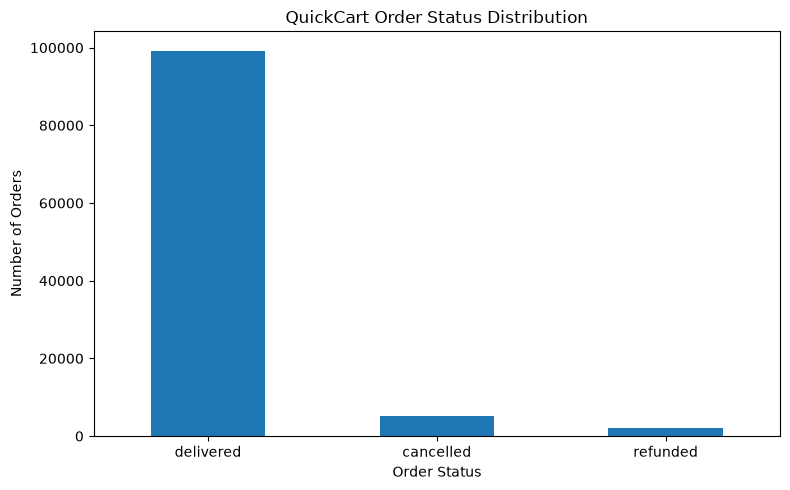

Business finding: QuickCart recorded 4.9% cancelled orders, so management should investigate cancellation drivers.


In [86]:
import matplotlib.pyplot as plt

status_counts = orders_data["status"].value_counts()

plt.figure(figsize=(8, 5))
status_counts.plot(kind="bar")
plt.title("QuickCart Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

total_orders = status_counts.sum()
cancelled_pct = (
    status_counts.get("cancelled", 0) / total_orders * 100
)

print(
    f"Business finding: QuickCart recorded "
    f"{cancelled_pct:.1f}% cancelled orders, "
    "so management should investigate cancellation drivers."
)

### Chart 2 — Recorded basket value by city

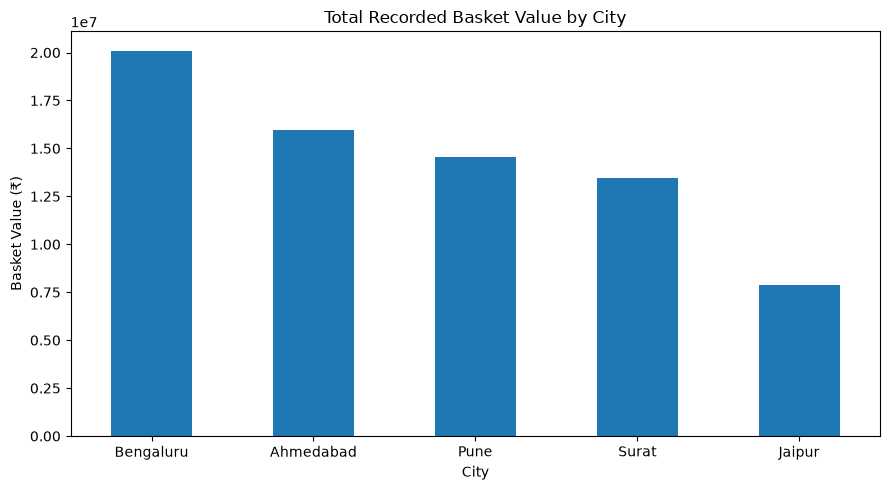

Business finding: Bengaluru has the highest total recorded basket value at ₹20,100,524.52. Management should investigate the factors driving its performance.


In [87]:
import matplotlib.pyplot as plt

# Create a cleaned copy of the customer data
customers_clean = customers.copy()

# Standardize city names
customers_clean["city"] = (
    customers_clean["city"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Map city names to consistent labels
city_mapping = {
    "bengaluru": "Bengaluru",
    "bangalore": "Bengaluru",
    "ahmedabad": "Ahmedabad",
    "pune": "Pune",
    "surat": "Surat",
    "jaipur": "Jaipur"
}

customers_clean["city"] = (
    customers_clean["city"]
    .map(city_mapping)
    .fillna(customers_clean["city"].str.title())
)

# Merge cleaned customer cities with orders
city_orders = orders_data.merge(
    customers_clean[["customer_id", "city"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Calculate total basket value by city
city_value = (
    city_orders.groupby("city")["basket_value"]
    .sum()
    .sort_values(ascending=False)
)

# Plot the chart
plt.figure(figsize=(9, 5))
city_value.plot(kind="bar")

plt.title("Total Recorded Basket Value by City")
plt.xlabel("City")
plt.ylabel("Basket Value (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Generate a finding from the actual results
top_city = city_value.idxmax()
top_value = city_value.max()

print(
    f"Business finding: {top_city} has the highest total "
    f"recorded basket value at ₹{top_value:,.2f}. "
    "Management should investigate the factors driving its performance."
)

### Chart 3 — Average orders per customer by membership plan

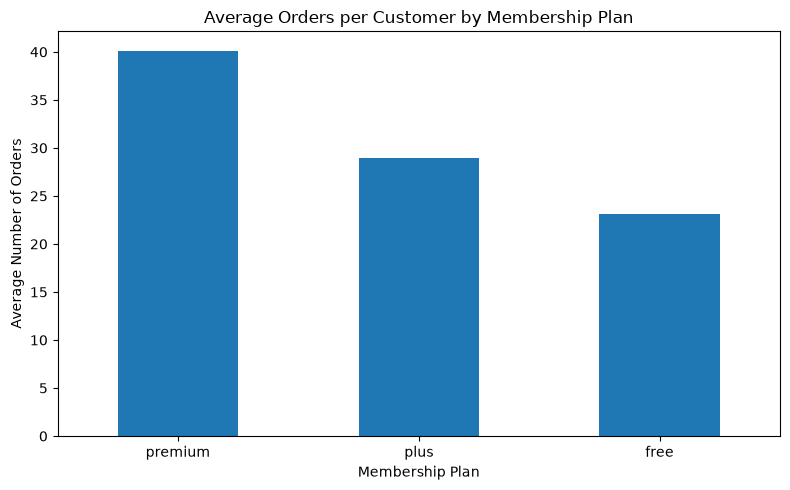

Business finding: The premium plan has the highest average orders per customer (40.13); management should investigate whether its benefits encourage repeat ordering.


In [88]:
customer_order_counts = (
    orders_data.groupby("customer_id")["order_id"]
    .nunique()
    .rename("order_count")
)

plan_activity = customers[
    ["customer_id", "plan_type"]
].merge(
    customer_order_counts,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

plan_activity["order_count"] = (
    plan_activity["order_count"].fillna(0)
)

avg_orders = (
    plan_activity.groupby("plan_type")["order_count"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
avg_orders.plot(kind="bar")
plt.title("Average Orders per Customer by Membership Plan")
plt.xlabel("Membership Plan")
plt.ylabel("Average Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

top_plan = avg_orders.idxmax()

print(
    f"Business finding: The {top_plan} plan has the highest "
    f"average orders per customer ({avg_orders.max():.2f}); "
    "management should investigate whether its benefits encourage repeat ordering."
)

### Chart 4 — Delivery time by order status

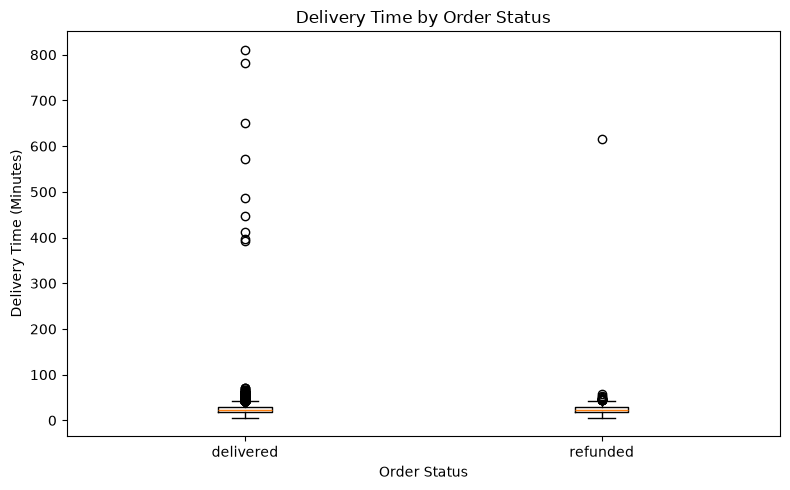

Business finding: Delivered orders have a median delivery time of 23.5 minutes, while 10% take longer than approximately 33.7 minutes; management should investigate the longest delivery delays.


In [89]:
delivery_data = orders_data.dropna(
    subset=["delivery_minutes", "status"]
).copy()

delivery_data = delivery_data[
    delivery_data["delivery_minutes"] > 0
]

statuses = [
    status for status in ["delivered", "cancelled", "refunded"]
    if status in delivery_data["status"].unique()
]

boxplot_data = [
    delivery_data.loc[
        delivery_data["status"] == status,
        "delivery_minutes"
    ]
    for status in statuses
]

plt.figure(figsize=(8, 5))
plt.boxplot(boxplot_data, tick_labels=statuses)
plt.title("Delivery Time by Order Status")
plt.xlabel("Order Status")
plt.ylabel("Delivery Time (Minutes)")
plt.tight_layout()
plt.show()

delivered_times = delivery_data.loc[
    delivery_data["status"] == "delivered",
    "delivery_minutes"
]

if not delivered_times.empty:
    median_delivery = delivered_times.median()
    p90_delivery = delivered_times.quantile(0.90)

    print(
        f"Business finding: Delivered orders have a median delivery "
        f"time of {median_delivery:.1f} minutes, while 10% take "
        f"longer than approximately {p90_delivery:.1f} minutes; "
        "management should investigate the longest delivery delays."
    )
else:
    print("No valid delivery-time records are available for delivered orders.")

### Chart 5 — Basket value versus discount

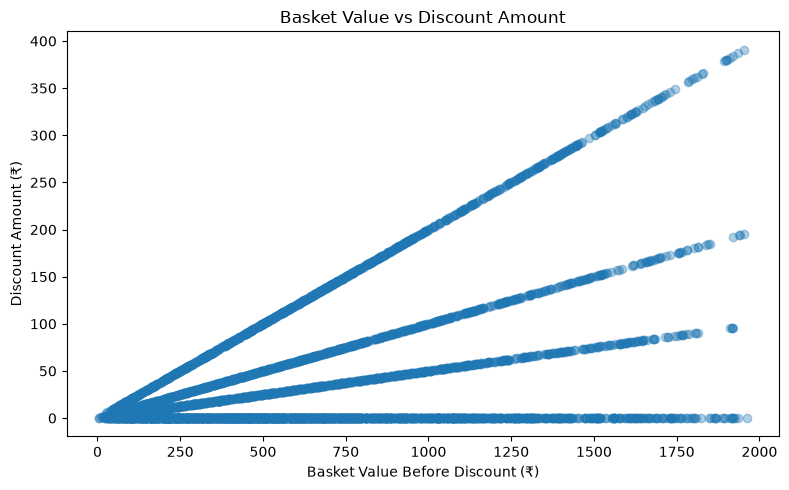

Business finding: Basket value and discount amount have a correlation of 0.45; management can use this relationship to review discount strategy, but correlation alone does not prove that discounts increase basket value.


In [90]:
discount_data = orders_data.loc[
    (orders_data["basket_value"] >= 0)
    & (orders_data["discount_amt"] >= 0),
    ["basket_value", "discount_amt"]
].dropna()

# Sample for a clearer scatter plot when the dataset is large.
plot_data = discount_data.sample(
    n=min(5000, len(discount_data)),
    random_state=42
)

plt.figure(figsize=(8, 5))
plt.scatter(
    plot_data["basket_value"],
    plot_data["discount_amt"],
    alpha=0.35
)
plt.title("Basket Value vs Discount Amount")
plt.xlabel("Basket Value Before Discount (₹)")
plt.ylabel("Discount Amount (₹)")
plt.tight_layout()
plt.show()

correlation = discount_data[
    ["basket_value", "discount_amt"]
].corr().iloc[0, 1]

print(
    f"Business finding: Basket value and discount amount have a "
    f"correlation of {correlation:.2f}; management can use this "
    "relationship to review discount strategy, but correlation alone "
    "does not prove that discounts increase basket value."
)

### Delivery drivers

In [91]:
import pandas as pd

# Keep orders with a valid delivery duration
delivery = orders_data.dropna(subset=["delivery_minutes"]).copy()

# 1. Distance vs delivery time
delivery["distance_group"] = pd.cut(
    delivery["distance_km"],
    bins=[-float("inf"), 2, 5, float("inf")],
    labels=["0–2 km", "2–5 km", "Above 5 km"]
)

distance_result = delivery.groupby(
    "distance_group", observed=True
)["delivery_minutes"].agg(["count", "mean", "median"])

# 2. Store workload vs delivery time
delivery["workload_group"] = pd.qcut(
    delivery["store_open_orders"],
    q=3,
    duplicates="drop"
)

workload_result = delivery.groupby(
    "workload_group", observed=True
)["delivery_minutes"].agg(["count", "mean", "median"])

# 3. Rain vs delivery time
rain_result = delivery.groupby("is_raining")[
    "delivery_minutes"
].agg(["count", "mean", "median"])

print("DISTANCE RESULTS")
print(distance_result.round(2))

print("\nSTORE WORKLOAD RESULTS")
print(workload_result.round(2))

print("\nRAIN RESULTS (0 = No rain, 1 = Rain)")
print(rain_result.round(2))

DISTANCE RESULTS
                count   mean  median
distance_group                      
0–2 km          49001  20.24    20.1
2–5 km          44566  26.23    26.1
Above 5 km       7785  36.27    35.8

STORE WORKLOAD RESULTS
                count   mean  median
workload_group                      
(0.999, 10.0]   34777  20.69    20.0
(10.0, 20.0]    34908  24.36    23.6
(20.0, 29.0]    31667  27.56    26.9

RAIN RESULTS (0 = No rain, 1 = Rain)
            count   mean  median
is_raining                      
0           95094  23.69    23.1
1            6258  30.30    29.5


### Customer feature table

In [92]:

# Work on copies
orders_copy = orders_data.copy()
customers_copy = customers.copy()

# Convert dates
orders_copy["order_ts"] = pd.to_datetime(
    orders_copy["order_ts"], errors="coerce"
)
customers_copy["signup_date"] = pd.to_datetime(
    customers_copy["signup_date"], errors="coerce"
)

# Define cutoff date
cutoff_date = orders_copy["order_ts"].max().normalize()

# Keep only orders available on or before the cutoff
orders_copy = orders_copy[
    orders_copy["order_ts"] < cutoff_date + pd.Timedelta(days=1)
].copy()

# Sort orders for latest-order calculations
orders_copy = orders_copy.sort_values("order_ts")

# Calculate customer-level order features
customer_features = orders_copy.groupby("customer_id").agg(
    last_order_date=("order_ts", "max"),
    frequency=("order_id", "nunique"),
    total_spend=("basket_value", "sum"),
    average_spend=("basket_value", "mean"),
    total_discount=("discount_amt", "sum"),
    rain_order_pct=("is_raining", "mean"),
    avg_delivery_minutes=("delivery_minutes", "mean"),
    cancelled_order_pct=(
        "status",
        lambda x: x.astype(str).str.strip().str.lower().eq("cancelled").mean()
    )
).reset_index()

# Recency in days
customer_features["recency_days"] = (
    cutoff_date - customer_features["last_order_date"].dt.normalize()
).dt.days

# Discount share: total discount divided by total basket value
customer_features["discount_share"] = (
    customer_features["total_discount"]
    / customer_features["total_spend"].replace(0, np.nan)
)

# Convert proportions to percentages
customer_features["rain_order_pct"] *= 100
customer_features["cancelled_order_pct"] *= 100

# Calculate customer tenure
customer_features = customer_features.merge(
    customers_copy[["customer_id", "signup_date"]],
    on="customer_id",
    how="right",
    validate="one_to_one"
)

customer_features["tenure_days"] = (
    cutoff_date - customer_features["signup_date"].dt.normalize()
).dt.days

# Remove helper columns
customer_features = customer_features.drop(
    columns=["last_order_date", "total_discount", "signup_date"]
)

# Keep one row per customer
customer_features = customer_features.drop_duplicates(
    subset="customer_id"
)

# Verify output
print("Cutoff date:", cutoff_date)
print("Customer table shape:", customer_features.shape)
print("Unique customers:", customer_features["customer_id"].nunique())
print("Duplicate customer IDs:", customer_features["customer_id"].duplicated().sum())

customer_features.head()

Cutoff date: 2026-06-29 00:00:00
Customer table shape: (4000, 10)
Unique customers: 4000
Duplicate customer IDs: 0


,customer_id,frequency,total_spend,average_spend,rain_order_pct,avg_delivery_minutes,cancelled_order_pct,recency_days,discount_share,tenure_days
0,C00001,65.0,47928.82,737.366462,12.307692,26.774603,3.076923,0.0,0.087964,337
1,C00002,11.0,7992.90,726.627273,27.272727,29.870000,9.090909,2.0,0.069499,131
2,C00003,11.0,9849.95,895.450000,0.000000,23.163636,0.000000,23.0,0.035263,167
3,C00004,129.0,82887.34,637.594923,5.384615,26.040323,4.615385,0.0,0.069152,232
4,C00005,62.0,39359.29,634.827258,1.612903,22.689831,4.838710,6.0,0.040348,234


### Vectorise

In [93]:
# Prepare the data


orders_data["order_ts"] = pd.to_datetime(
    orders_data["order_ts"], errors="coerce"
)

# Cutoff date: latest date in the dataset
cutoff_date = orders_data["order_ts"].max().normalize()

# Find the last order date for each customer
last_order = (
    orders_data.dropna(subset=["order_ts"])
    .groupby("customer_id")["order_ts"]
    .max()
)

print("Cutoff date:", cutoff_date)
print("Customers with valid order dates:", len(last_order))

Cutoff date: 2026-06-29 00:00:00
Customers with valid order dates: 3950


In [94]:
#Calculate recency using vectorization

def recency_loop():
    recency = {}

    for customer_id, order_date in last_order.items():
        recency[customer_id] = (
            cutoff_date - order_date.normalize()
        ).days

    return pd.Series(recency, name="recency_days")

recency_loop().head()

C00001     0
C00002     2
C00003    23
C00004     0
C00005     6
Name: recency_days, dtype: int64

In [95]:
# Calculate recency using vectorization

def recency_vectorized():
    return (
        cutoff_date - last_order.dt.normalize()
    ).dt.days

vectorized_result = recency_vectorized()

print(vectorized_result.head())

customer_id
C00001     0
C00002     2
C00003    23
C00004     0
C00005     6
Name: order_ts, dtype: int64


In [96]:
#Calculate recency using a loop

def recency_loop():
    result = {}

    for customer_id, order_date in last_order.items():
        result[customer_id] = (
            cutoff_date - order_date.normalize()
        ).days

    return pd.Series(result, name="recency_days")

loop_result = recency_loop()

print(loop_result.head())

C00001     0
C00002     2
C00003    23
C00004     0
C00005     6
Name: recency_days, dtype: int64


In [97]:
#

import timeit

vectorized_time = min(
    timeit.repeat(
        recency_vectorized,
        number=10,
        repeat=5
    )
) / 10

loop_time = min(
    timeit.repeat(
        recency_loop,
        number=10,
        repeat=5
    )
) / 10

print("\nExecution time comparison:")
print(f"Vectorized: {vectorized_time:.6f} seconds")
print(f"Loop:       {loop_time:.6f} seconds")


Execution time comparison:
Vectorized: 0.001076 seconds
Loop:       0.066215 seconds


In [98]:
speedup = loop_time / vectorized_time

print(f"Speedup: {speedup:.2f}x")

# Verify both methods produce identical results
pd.testing.assert_series_equal(
    vectorized_result.sort_index(),
    loop_result.sort_index(),
    check_names=False
)

print("Verification successful: both results match.")

Speedup: 61.56x
Verification successful: both results match.


In [100]:
# Calculate speedup
speedup = loop_time / vectorized_time

print(f"Vectorized time: {vectorized_time:.6f} seconds")
print(f"Loop time:       {loop_time:.6f} seconds")
print(f"Speedup:         {speedup:.2f}x")

# Verify both methods produce identical results
pd.testing.assert_series_equal(
    vectorized_result.sort_index(),
    loop_result.sort_index(),
    check_names=False
)

print("Verification successful: both results match.")

Vectorized time: 0.001076 seconds
Loop time:       0.066215 seconds
Speedup:         61.56x
Verification successful: both results match.


In [101]:
pd.testing.assert_series_equal(
    vectorized_result.sort_index(),
    loop_result.sort_index(),
    check_names=False
)

print("Both methods return identical recency values.")

Both methods return identical recency values.
